# Makroekonomik Göstergelere Göre Ülkelerin Kredi Risk Sınıflandırması
## K-Nearest Neighbors (KNN) Algoritması | World Bank (WDI) & IMF (WEO) Verileri

**Proje türü:** Denetimli makine öğrenmesi – çok sınıflı sınıflandırma  
**Veri kaynağı:** World Bank (WDI), IMF World Economic Outlook (WEO)
**Analiz birimi:** Ülke-yıl gözlemi  
**Model:** K-Nearest Neighbors (KNN)

### Araştırma amacı
Bu çalışmada ülkelerin makroekonomik göstergelerinden yararlanılarak göreli bir makroekonomik risk profili oluşturulacak ve KNN algoritmasıyla düşük, orta ve yüksek risk sınıfları tahmin edilecektir.

> **Önemli metodolojik not:** World Bank WDI, doğrudan egemen kredi notu (S&P, Moody’s veya Fitch notu) sağlamaz. Bu nedenle bu notebook'ta hedef değişken, seçilen makroekonomik göstergelerden açıkça tanımlanan **proxy (temsili) risk kuralları** ile üretilecektir. Model çıktısı gerçek bir kredi notu veya yatırım tavsiyesi değildir. Gerçek kredi notlarıyla doğrulama yapılacaksa ayrıca derecelendirme kuruluşlarının tarihsel not verileri gerekir.

## 1. Çalışma tasarımı ve göstergeler

Aşağıdaki WDI-World Development Indicators (Dünya Kalkınma Göstergeleri) göstergeleri kullanılacaktır.

| Gösterge | WDI kodu | Beklenen risk yönü |
|---|---|---|
| Reel GSYH büyümesi (%) | `NY.GDP.MKTP.KD.ZG` | Düşük büyüme daha riskli |
| Enflasyon, tüketici fiyatları (%) | `FP.CPI.TOTL.ZG` | Yüksek enflasyon daha riskli |
| İşsizlik, ILO tahmini (%) | `SL.UEM.TOTL.ZS` | Yüksek işsizlik daha riskli |
| Genel yönetim brüt kamu borcu / GSYH % | `GC.DOD.TOTL.GD.ZS` | Yüksek borç daha riskli |
| Cari işlemler dengesi / GSYH (%) | `BN.CAB.XOKA.GD.ZS` | Büyük açık daha riskli |
| Kişi başına GSYH - sabit uluslararası $ | `NY.GDP.PCAP.KD` | Düşük gelir daha riskli |

**Kapsam notu:** Dünya Bankası WDI kamu borcu serisindeki (GC.DOD.TOTL.GD.ZS) ülke kapsamı kısıtlı olduğundan, kamu borcu göstergesi IMF World Economic Outlook (GGXWDG_NGDP - Genel yönetim brüt kamu borcu / GSYH) veri setiyle tamamlanmıştır.

## 2. Kütüphaneler ve çalışma ayarları


In [2]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn requests

Note: you may need to restart the kernel to use updated packages.


In [3]:
import warnings
warnings.filterwarnings("ignore")

import requests
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
START_YEAR = 2010
END_YEAR = 2023  

## 3. Verilerin okunması ve birleştirilmesi

In [4]:
import glob
import os
import pandas as pd

# 1. Dosya okuma yardımcı fonksiyonu (Dosyalar doğrudan FINAL ana klasöründe olduğu için yol "." olarak ayarlandı)
def owid_oku(dosya_adi, yeni_sutun_adi):
    df = pd.read_csv(dosya_adi)
    # Sadece 3 harfli ISO3 ülke koduna sahip gerçek ülkeleri tut (bölgesel toplamları ele)
    df = df[df["Code"].notna() & (df["Code"].astype(str).str.len() == 3)].copy()
    
    # OWID dosyalarında ana gözlem sütunu 4. sütundur (index 3)
    deger_sutunu = df.columns[3]
    
    df = df[["Code", "Entity", "Year", deger_sutunu]].rename(
        columns={
            "Code": "iso3",
            "Entity": "country",
            "Year": "year",
            deger_sutunu: yeni_sutun_adi
        }
    )
    df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")
    df[yeni_sutun_adi] = pd.to_numeric(df[yeni_sutun_adi], errors="coerce")
    return df

# 2. 5 OWID CSV dosyasını oku
tum_csvler = glob.glob("*.csv")
eslestirme = {
    "real-gdp-growth": "gdp_growth",
    "inflation-of-consumer-prices": "inflation",
    "unemployment-rate": "unemployment",
    "current-account-balance": "current_account",
    "gdp-per-capita-worldbank": "gdp_per_capita"
}

owid_tablolar = []
for anahtar, sutun_adi in eslestirme.items():
    eslesen = [f for f in tum_csvler if anahtar in f.lower()]
    if not eslesen:
        raise FileNotFoundError(f"'{anahtar}' içeren CSV dosyası bulunamadı!")
    print(f"Okunuyor: {eslesen[0]} -> {sutun_adi}")
    owid_tablolar.append(owid_oku(eslesen[0], sutun_adi))

# 3. IMF Kamu Borcu (imf_borc.csv) dosyasını oku ve uzun (long) formata çevir
df_borc_raw = pd.read_csv("imf_borc.csv", sep=";")
yil_sutunlari = [c for c in df_borc_raw.columns if c.isdigit()]

df_borc = df_borc_raw.melt(
    id_vars=["ISO"],
    value_vars=yil_sutunlari,
    var_name="year",
    value_name="government_debt"
).rename(columns={"ISO": "iso3"})

df_borc["year"] = pd.to_numeric(df_borc["year"], errors="coerce").astype("Int64")
df_borc["government_debt"] = pd.to_numeric(
    df_borc["government_debt"].astype(str).str.replace(",", "."), errors="coerce"
)
df_borc = df_borc[df_borc["iso3"].notna() & (df_borc["iso3"].astype(str).str.len() == 3)]

# 4. Tüm 6 göstergeyi birleştir ve notebook'taki START_YEAR - END_YEAR aralığına filtrele
data = owid_tablolar[0]
for tablo in owid_tablolar[1:]:
    data = data.merge(tablo.drop(columns=["country"]), on=["iso3", "year"], how="outer")

data = data.merge(df_borc, on=["iso3", "year"], how="left")

data = data[(data["year"] >= START_YEAR) & (data["year"] <= END_YEAR)].copy()
data = data.sort_values(["iso3", "year"]).reset_index(drop=True)

# 5. Sonucu kontrol et
print("\nBirleştirilmiş Veri Boyutu:", data.shape)
print("\nEksik Değer Sayıları:")
print(data.isna().sum())
display(data[data["iso3"] == "TUR"])



# Eksik ülke isimlerini (country) diğer tablolardan tamamla
ulke_sozlugu = dict(zip(df_borc_raw["ISO"], df_borc_raw["Country"]))
for tablo in owid_tablolar:
    gecerli = tablo.dropna(subset=["iso3", "country"]).drop_duplicates("iso3")
    ulke_sozlugu.update(dict(zip(gecerli["iso3"], gecerli["country"])))

data["country"] = data["country"].fillna(data["iso3"].map(ulke_sozlugu))

Okunuyor: real-gdp-growth.csv -> gdp_growth
Okunuyor: inflation-of-consumer-prices.csv -> inflation
Okunuyor: unemployment-rate.csv -> unemployment
Okunuyor: current-account-balance-as-a-proportion-of-gdp.csv -> current_account
Okunuyor: gdp-per-capita-worldbank.csv -> gdp_per_capita

Birleştirilmiş Veri Boyutu: (2926, 9)

Eksik Değer Sayıları:
iso3                 0
country            208
year                 0
gdp_growth         222
inflation          351
unemployment       326
current_account    363
gdp_per_capita     159
government_debt    256
dtype: int64


,iso3,country,year,gdp_growth,inflation,unemployment,current_account,gdp_per_capita,government_debt
2660,TUR,Turkey,2010,8.542,8.566,11.879,-5.700,"19,897.447",39.511
2661,TUR,Turkey,2011,10.980,6.472,9.789,-8.810,"21,760.430",35.912
2662,TUR,Turkey,2012,4.808,8.892,9.210,-4.720,"22,517.715",32.227
2663,TUR,Turkey,2013,8.488,7.493,9.713,-5.130,"24,117.312",30.892
2664,TUR,Turkey,2014,4.601,8.855,9.901,-3.410,"24,888.852",28.277
2665,TUR,Turkey,2015,5.806,7.671,10.304,-2.470,"25,984.803",27.163
2666,TUR,Turkey,2016,3.324,7.775,10.899,-2.550,"26,489.645",27.747
2667,TUR,Turkey,2017,7.826,11.144,10.919,-4.070,"28,194.688",27.777
2668,TUR,Turkey,2018,3.468,16.332,10.956,-1.850,"28,780.303",29.860
2669,TUR,Turkey,2019,1.302,15.177,13.730,1.940,"28,741.053",32.390


## 3. Veri setinin ilk incelemesi

In [5]:
# df üzerinde güncellediğimiz veriyi ana 'data' değişkenine de aktaralım:
data = data.copy()

print("Başarılı! Veriler 'data' tablosuna aktarıldı.")
print("Boyut:", data.shape)
print("\nDeğişken türleri:")
display(data.dtypes.to_frame("dtype"))
print("\nTanımlayıcı istatistikler:")
print("\nTanımlayıcı istatistikler:")

numeric_data = data.select_dtypes(include="number")

display(numeric_data.describe().T)
print("\nEksik gözlem sayısı:")
display(data.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Başarılı! Veriler 'data' tablosuna aktarıldı.
Boyut: (2926, 9)

Değişken türleri:


,dtype
iso3,str
country,str
year,Int64
gdp_growth,float64
inflation,float64
unemployment,float64
current_account,float64
gdp_per_capita,float64
government_debt,float64



Tanımlayıcı istatistikler:

Tanımlayıcı istatistikler:


,count,mean,std,min,25%,50%,75%,max
year,"2,926.000","2,016.500",4.032,"2,010.000","2,013.000","2,016.500","2,020.000","2,023.000"
gdp_growth,"2,704.000",3.039,6.003,-54.402,1.193,3.315,5.494,86.827
inflation,"2,575.000",6.451,20.363,-6.687,1.386,3.232,6.331,557.202
unemployment,"2,600.000",7.893,5.987,0.100,3.667,5.847,10.760,36.472
current_account,"2,563.000",-2.281,13.735,-60.880,-7.420,-2.600,1.940,235.750
gdp_per_capita,"2,767.000","25,315.425","25,989.963",988.019,"5,710.086","15,772.837","37,268.111","174,569.520"
government_debt,"2,670.000",54.881,38.334,0.000,31.229,46.895,69.515,360.851



Eksik gözlem sayısı:


,missing_count
current_account,363
inflation,351
unemployment,326
government_debt,256
gdp_growth,222
gdp_per_capita,159
iso3,0
country,0
year,0


### 3.1 Eksik veri oranları

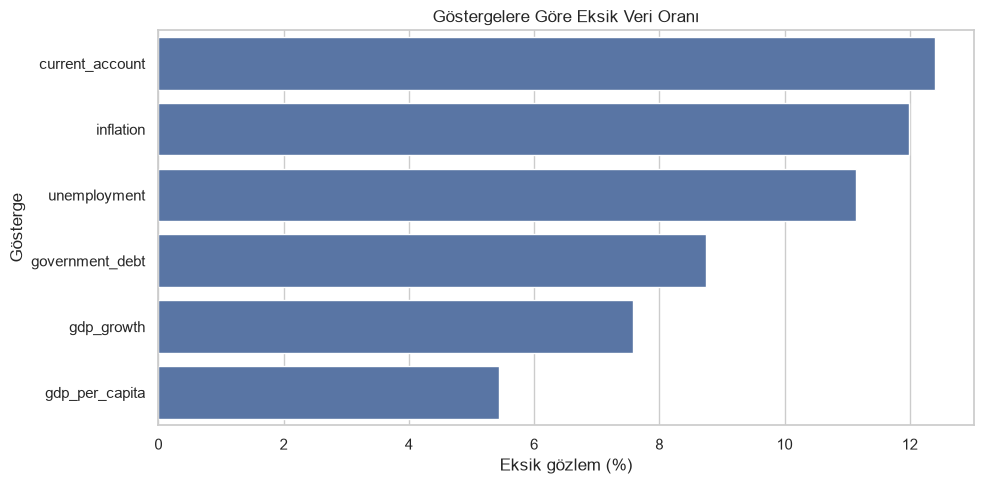

In [6]:
# Sütun isimlerimizi dinamik olarak kontrol edip eksik oranını hesaplayalım
ilgili_sutunlar = [col for col in ['gdp_growth', 'inflation', 'unemployment', 'government_debt', 'current_account', 'gdp_per_capita'] if col in data.columns]

missing_rate = data[ilgili_sutunlar].isna().mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 5))
sns.barplot(x=missing_rate.values, y=missing_rate.index)
plt.xlabel("Eksik gözlem (%)")
plt.ylabel("Gösterge")
plt.title("Göstergelere Göre Eksik Veri Oranı")
plt.tight_layout()
plt.show()

## 4. Veri temizleme ve analiz örneklemi

WDI API'sinden üç harfli ISO3 koduna sahip ve World Bank metadata bilgisinde bölge/toplam olmayan ülke kayıtları alınır. Modelleme için altı göstergenin tamamı dolu olan ülke-yıl gözlemleri kullanılır. Tam gözlem yaklaşımı örneklemi küçültebilir ve eksiklikler sistematikse seçilim yanlılığı oluşturabilir. Eksik veri oranları bu nedenle ayrıca raporlanır.\n

In [7]:
feature_cols = [
    "gdp_growth",
    "inflation",
    "unemployment",
    "government_debt",
    "current_account",
    "gdp_per_capita"
]

# Aynı ülke-yıl için olası yinelenen kayıtları kontrol et
print("Yinelenen ülke-yıl:", data.duplicated(["iso3", "year"]).sum())

# ISO3 ve ülke-yıl bazında tekil kayıt
data = data.drop_duplicates(["iso3", "year"]).copy()

model_data = data.dropna(subset=feature_cols).copy()
model_data = model_data.replace([np.inf, -np.inf], np.nan).dropna(subset=feature_cols)

print("Tam gözlem sayısı:", len(model_data))
print("Ülke sayısı:", model_data["iso3"].nunique())
print("Yıl aralığı:", model_data["year"].min(), "-", model_data["year"].max())
display(model_data.head())

Yinelenen ülke-yıl: 0
Tam gözlem sayısı: 2236
Ülke sayısı: 167
Yıl aralığı: 2010 - 2023


,iso3,country,year,gdp_growth,inflation,unemployment,current_account,gdp_per_capita,government_debt
14,AFG,Afghanistan,2010,8.438,2.179,7.809,-3.640,"2,848.586",7.697
15,AFG,Afghanistan,2011,6.479,11.804,7.830,-12.620,"2,757.052",7.501
16,AFG,Afghanistan,2012,13.968,6.441,7.875,-25.870,"2,985.319",6.759
17,AFG,Afghanistan,2013,5.683,7.386,7.921,-25.290,"3,046.580",6.904
18,AFG,Afghanistan,2014,2.697,4.674,7.915,-15.770,"3,017.943",8.700


## 6. Keşifsel veri analizi (EDA)

### 6.1 Göstergelerin dağılımları

Makroekonomik göstergeler aykırı değerlere ve çarpık dağılımlara sahip olabilir. KNN mesafe tabanlı olduğundan ölçekleme önemlidir; uç değerlerin etkisi de sonuçların yorumunda dikkate alınmalıdır.

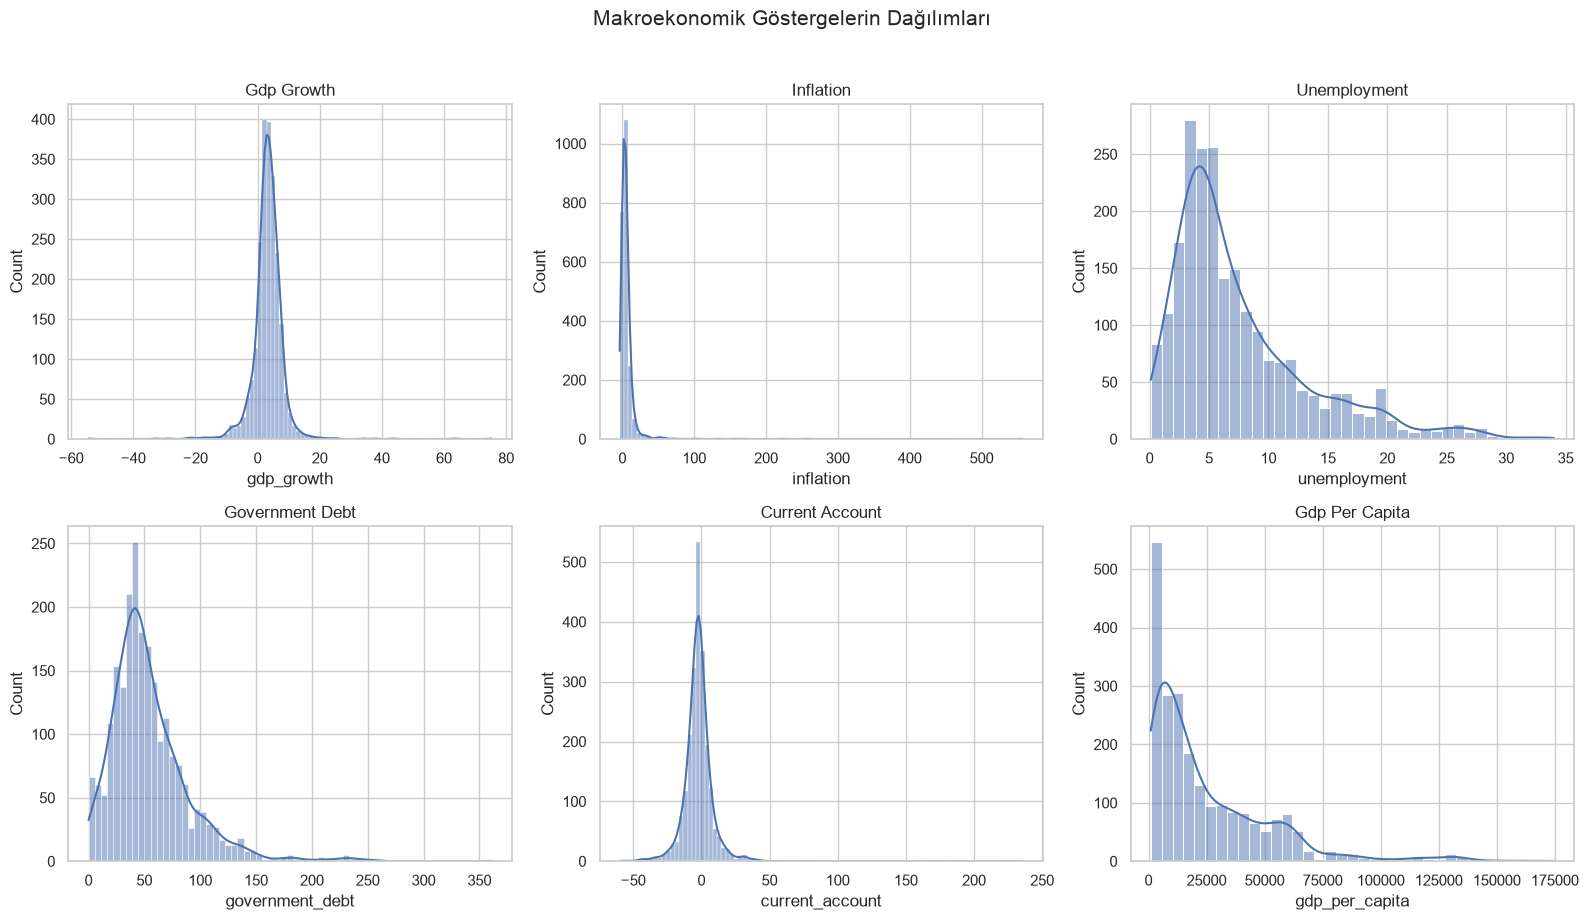

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, feature_cols):
    sns.histplot(model_data[col], kde=True, ax=ax)
    ax.set_title(col.replace("_", " ").title())
plt.suptitle("Makroekonomik Göstergelerin Dağılımları", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

Grafikteki 6 makroekonomik göstergenin dağılımını incelediğimizde, neredeyse hiçbirinin kusursuz bir normal dağılıma (çan eğrisine) sahip olmadığını ve ciddi **uç değerler (outliers)** barındırdığını görüyoruz. KNN gibi mesafe tabanlı algoritmalar bu uç değerlerden ve ölçek farklarından çok etkilendiği için bu analizin sonuçları modelleme stratejisi açısından kritik öneme sahiptir.

Değişken bazında öne çıkanlar:

* **GDP Growth (Büyüme):** Sıfırın hemen sağında (pozitif büyüme) çok sivri bir tepe noktasına (leptokurtic) sahiptir. Dağılımın hem sol tarafında (-60'lara varan ekonomik kriz/daralma dönemleri) hem de sağ tarafında (+80'lere uzanan ani sıçramalar) ciddi kuyruklar var.

* **Inflation (Enflasyon):** Şiddetli bir şekilde sağa çarpıktır (right-skewed). Dünya genelinde ülkelerin büyük çoğunluğu %0-20 bandında yığılmışken, sağa doğru 500'leri aşan hiperenflasyon uç değerleri (örn. Venezuela, Zimbabve gibi istisnai durumlar) grafiğin ölçeğini inanılmaz derecede genişletmiştir.

* **Unemployment (İşsizlik):** Yine sağa çarpık bir yapı vardır; verilerin çoğu %3 ile %10 arasında kümelenmiş (%5 civarında zirve yapıyor). Ancak %30'ları aşan aşırı işsizlik örnekleri kuyruğu sağa çekiyor.

* **Government Debt (Kamu Borcu):** %40-60 bandında bir yığılma var ancak dağılım yine sağa çarpıktır. GSYH'nin %300'üne yaklaşan (Japonya, Yunanistan vb. borç krizi örnekleri) uzun bir sağ kuyruk görülüyor.

* **Current Account (Cari Denge):** Sıfır noktası civarında çok sivri bir yığılma vardır. Ancak özellikle pozitif yönde (cari fazla) +200'leri aşan çok anormal uç değerler mevcuttur.

* **GDP Per Capita (Kişi Başına GSYH):** Keskin bir şekilde sağa çarpıktır; veri setindeki çoğu gözlem düşük ve orta gelir seviyesinde (grafiğin soluna yapışık) yığılmıştır. 100.000 doları aşan yüksek gelirli istisnai ülkeler uzun bir sağ kuyruk oluşturmuştur.

**Modelleme İçin Çıkarım:**
Değerler arasında devasa ölçek farkları vardır (Büyüme -60 ile 80 arasındayken, Kişi Başına GSYH 175.000'lere ulaşıyor). KNN algoritması mesafeleri ölçerken rakamı büyük olan GSYH gibi değişkenlerin ağırlığını haksız yere artırır. Bu yüzden modellemeden önce `StandardScaler` kullanımı **zorunludur**.

### 6.2 Korelasyon analizi

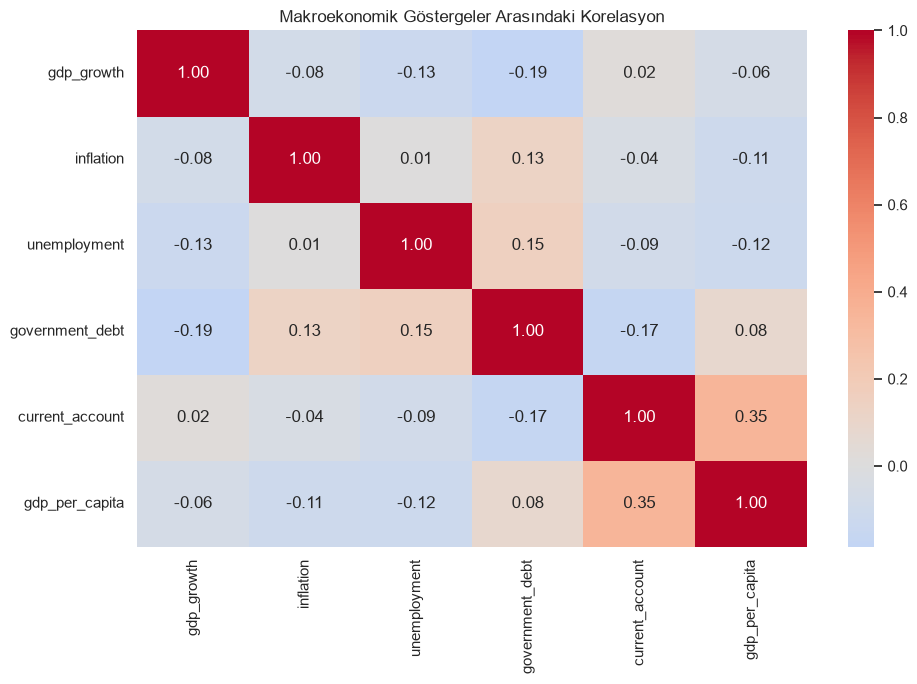

In [9]:
plt.figure(figsize=(10, 7))
corr = model_data[feature_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Makroekonomik Göstergeler Arasındaki Korelasyon")
plt.tight_layout()
plt.show()

### Korelasyon Analizi Değerlendirmesi

Yukarıdaki korelasyon matrisi incelendiğinde, makroekonomik göstergeler arasındaki ilişkiler şu şekilde özetlenebilir:

* **Çoklu Doğrusallık (Multicollinearity) Riski Yoktur:** Tablodaki en yüksek korelasyon değeri 0.35 seviyesindedir. Herhangi iki değişken arasında (örn. >0.70) yüksek bir ilişki bulunmaması, makine öğrenmesi modeli (KNN) için oldukça olumludur. Bu sayede hiçbir değişken birbirinin kopyası durumunda değildir ve her biri modele tamamen benzersiz bir makroekonomik bilgi sunmaktadır.

* **En Güçlü Pozitif İlişki (0.35):** Kişi başına GSYH (`gdp_per_capita`) ile cari işlemler dengesi (`current_account`) arasında tablodaki en güçlü pozitif korelasyon görülmektedir[cite: 17]. Bu durum, gelir seviyesi yüksek ülkelerin cari fazla verme veya dış dengelerini daha sağlam tutma eğiliminde olduğunu göstermektedir.

* **Borç ve Büyüme Arasındaki Negatif İlişki (-0.19):** Kamu borcu (`government_debt`) ile ekonomik büyüme (`gdp_growth`) arasında tablodaki en güçlü negatif ilişki mevcuttur[cite: 17]. Bu bulgu, artan kamu borç yükünün ekonomik büyümeyi baskıladığına/yavaşlattığına dair temel makroekonomik teorilerle uyumludur.

### 6.3 Yıllara göre gösterge eğilimleri

Aşağıdaki grafikler ülke ortalamalarının yıllara göre değişimini gösterir. Basit ortalama, ülke büyüklüklerini dikkate almaz; bu nedenle küresel toplam/ ağırlıklı ortalama olarak yorumlanmamalıdır.

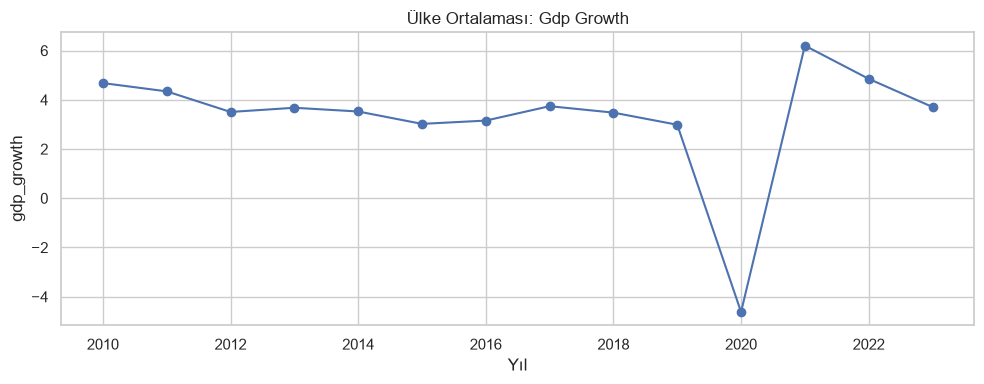

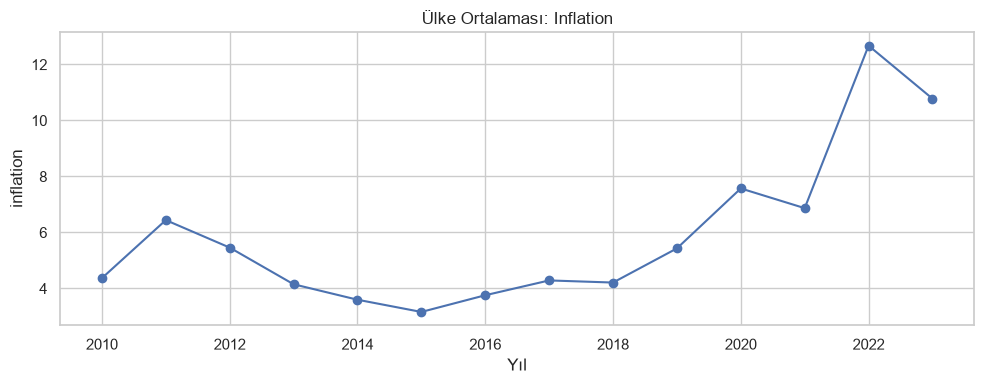

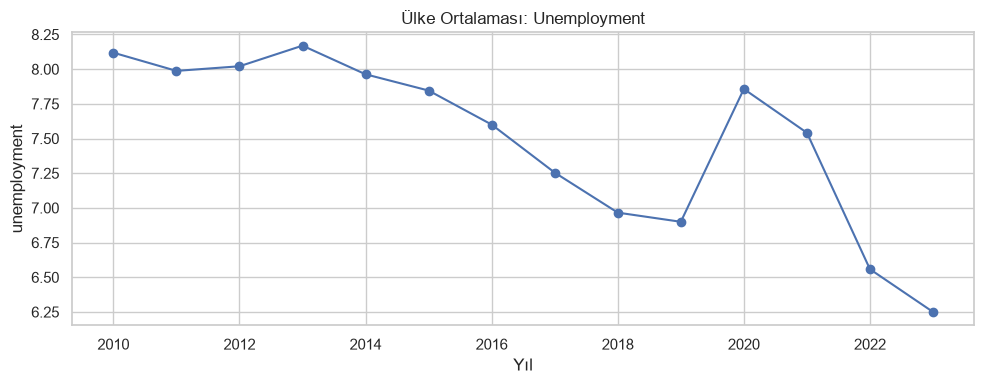

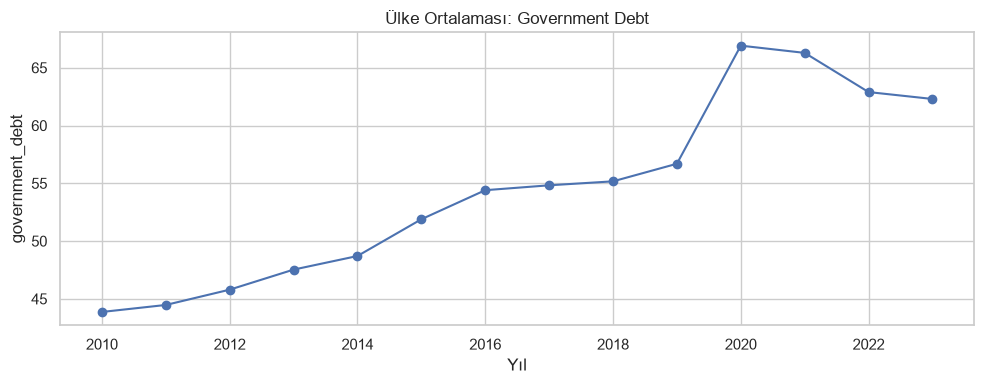

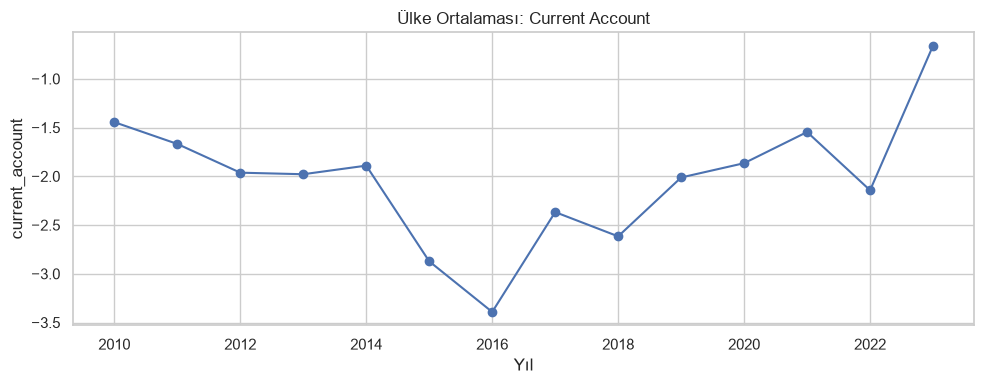

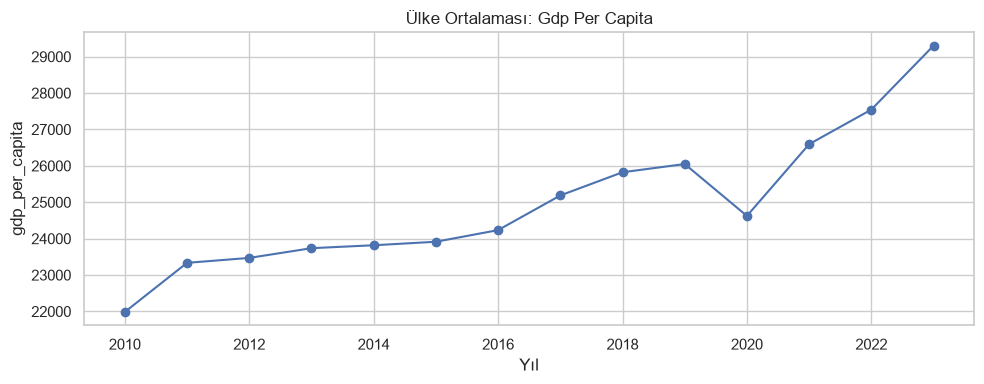

In [10]:
annual_means = model_data.groupby("year")[feature_cols].mean()
for col in feature_cols:
    plt.figure(figsize=(10, 4))
    annual_means[col].plot(marker="o")
    plt.title(f"Ülke Ortalaması: {col.replace('_', ' ').title()}")
    plt.xlabel("Yıl")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

### Zaman Serisi Eğilimleri Değerlendirmesi

Ülke ortalamalarının yıllara göre değişimi incelendiğinde, küresel makroekonomik döngülere dair şu iki majör şok grafiklerek açıkça yansımıştır:

* **2020 Covid-19 Ekonomik Daralması (Büyüme Şoku):** 2010-2019 yılları arasında ortalama %3-4 bandında stabil seyreden küresel büyüme (GDP Growth), 2020 yılında pandeminin etkisiyle sert bir şekilde -%4 seviyelerine çakılmıştır. 2021 yılındaki %6'yı aşan baz etkisi sıçramasının ardından, büyüme oranları 2022-2023 döneminde tekrar normalleşme eğilimine girmiştir.

* **2022 Küresel Enflasyon Krizi:** 2020 yılına kadar %4-6 bandında görece yatay seyreden ortalama enflasyon, pandemideki tedarik zinciri kırılmaları, enerji krizleri ve genişleyici para politikalarının gecikmeli etkisiyle 2021'de yükselişe geçmiş, 2022 yılında ise ortalama %12'nin üzerine çıkarak keskin bir zirve yapmıştır. 2023 itibarıyla küresel parasal sıkılaşma adımlarının etkisiyle enflasyonun ivme kaybettiği görülmektedir.

## 7. Hedef değişken: temsili makroekonomik risk sınıfı

World Bank WDI doğrudan egemen kredi derecelendirme notu vermediği için hedef sınıfı makroekonomik risk göstergelerinden türetiyoruz. Aşağıdaki puanlama **araştırmacı tarafından belirlenmiş bir operasyonel tanımdır**; evrensel kabul görmüş kredi riski standardı değildir.

Her gözlem için beş risk bileşeni hesaplanır:
- Büyüme: negatif büyüme 1 puan, büyüme %0–2 arası 0.5 puan.
- Enflasyon: %10 üzeri 1 puan, %5–10 arası 0.5 puan.
- İşsizlik: %15 üzeri 1 puan, %10–15 arası 0.5 puan.
- Kamu borcu: GSYH'nin %90'ı üzeri 1 puan, %60–90 arası 0.5 puan.
- Cari denge: GSYH'nin %-5'inin altı 1 puan, %-5 ile %-3 arası 0.5 puan.

Toplam puan 0–5 aralığındadır. 0–1: düşük, 1.5–2.5: orta, 3–5: yüksek risk olarak sınıflandırılır. Bu eşikler modelleme amacıyla seçilmiştir ve duyarlılık analizine tabidir.

**Önemli:** Bu yaklaşım bir proxy etiketi üretir. Hedefi oluşturan göstergeleri aynı anda modele girdi olarak vermek, modelin bağımsız kredi notu öğrenmesinden ziyade tanımladığımız kuralı yeniden üretmesine yol açar. Bu nedenle aşağıda hedef puanını oluşturan beş gösterge model girdilerinden çıkarılmış; modelde kişi başına GSYH kullanılmıştır. Ayrıca bu sınıflandırma kredi riskinin tüm boyutlarını kapsamaz.

In [11]:
def risk_score(row):
    score = 0
    # GSYH büyümesi: düşük büyüme risk göstergesi
    score += 1 if row["gdp_growth"] < 0 else (0.5 if row["gdp_growth"] < 2 else 0)
    # Enflasyon
    score += 1 if row["inflation"] > 10 else (0.5 if row["inflation"] > 5 else 0)
    # İşsizlik
    score += 1 if row["unemployment"] > 15 else (0.5 if row["unemployment"] > 10 else 0)
    # Kamu borcu / GSYH
    score += 1 if row["government_debt"] > 90 else (0.5 if row["government_debt"] > 60 else 0)
    # Cari işlemler dengesi / GSYH (negatif açık)
    score += 1 if row["current_account"] < -5 else (0.5 if row["current_account"] < -3 else 0)
    return score

model_data["risk_score"] = model_data.apply(risk_score, axis=1)

def assign_risk(score):
    if score <= 2.0:
        return "Güvenli"
    else:
        return "Riskli"

model_data["risk_class"] = model_data["risk_score"].apply(assign_risk)

display(model_data[["country", "year", "risk_score", "risk_class"]].head(10))
print("\nSınıf dağılımı:")
display(model_data["risk_class"].value_counts().to_frame("gözlem_sayısı"))

,country,year,risk_score,risk_class
14,Afghanistan,2010,0.500,Güvenli
15,Afghanistan,2011,2.000,Güvenli
16,Afghanistan,2012,1.500,Güvenli
17,Afghanistan,2013,1.500,Güvenli
18,Afghanistan,2014,1.000,Güvenli
19,Afghanistan,2015,1.500,Güvenli
20,Afghanistan,2016,1.500,Güvenli
21,Afghanistan,2017,1.500,Güvenli
22,Afghanistan,2018,2.000,Güvenli
23,Afghanistan,2019,1.500,Güvenli



Sınıf dağılımı:


,gözlem_sayısı
risk_class,
Güvenli,1916
Riskli,320


### 7.1 Risk sınıflarının dağılımı

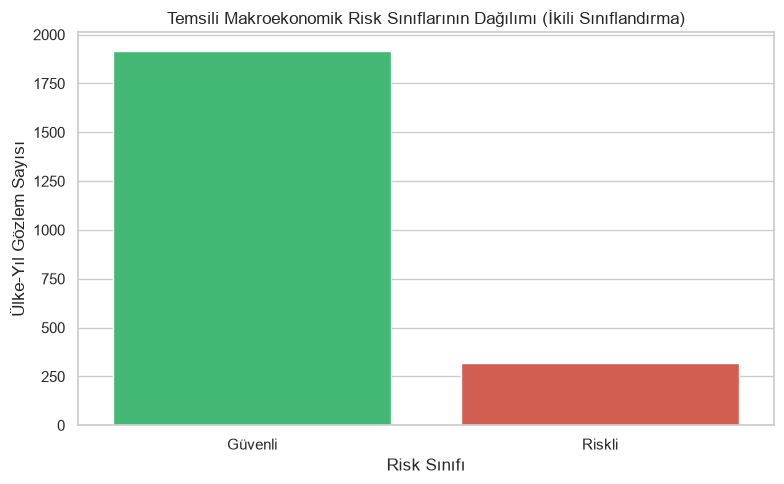

In [12]:
plt.figure(figsize=(8, 5))
order = ["Güvenli", "Riskli"]
sns.countplot(data=model_data, x="risk_class", order=order, palette=["#2ecc71", "#e74c3c"])
plt.title("Temsili Makroekonomik Risk Sınıflarının Dağılımı (İkili Sınıflandırma)")
plt.xlabel("Risk Sınıfı")
plt.ylabel("Ülke-Yıl Gözlem Sayısı")
plt.tight_layout()
plt.show()

## 8. Model değişkenlerinin belirlenmesi

Hedef sınıf, büyüme, enflasyon, işsizlik, kamu borcu ve cari denge göstergelerinden üretildiği için bu beş değişkeni modele girdi olarak vermek **hedef sızıntısı** yaratır. Bu nedenle KNN modelinde yalnızca hedef puanının hesaplanmasında kullanılmayan `gdp_per_capita` (kişi başına GSYH) değişkeni kullanılır.

Bu tercih sızıntıyı önler; ancak tek değişkenli modelin ayırt etme gücünü sınırlayabilir. Daha kapsamlı ve akademik olarak güçlü bir çalışma için hedef etiketin bağımsız tarihsel egemen kredi notlarından oluşturulması ve bu altı gösterge dahil uygun makroekonomik girdilerin kullanılması önerilir.\n

In [13]:
# Hedefi oluşturan beş gösterge X'e dahil edilmez.
X = model_data[["gdp_per_capita"]].copy()
y = model_data["risk_class"].copy()
groups = model_data.loc[X.index, "iso3"].copy()

print("X boyutu:", X.shape)
print("y boyutu:", y.shape)
print("Model girdileri:", X.columns.tolist())
print("Sınıflar:", sorted(y.unique()))


X boyutu: (2236, 1)
y boyutu: (2236,)
Model girdileri: ['gdp_per_capita']
Sınıflar: ['Güvenli', 'Riskli']


## 9. Eğitim ve test verisine ayırma

Aynı ülkenin farklı yıllarının hem eğitim hem test kümesine düşmesi performansı olduğundan yüksek gösterebilir. Bu nedenle ülke kodu (`iso3`) grup değişkeni olarak kullanılır ve `StratifiedGroupKFold` ile aynı ülke iki kümeye birden girmeyecek şekilde ayrım yapılır. Bu değerlendirme daha önce görülmemiş ülkelere genellemeyi hedefler; gelecek yılları tahmin etme senaryosunu ölçmez.\n

In [14]:
# Her risk sınıfında en az iki farklı ülke bulunmalı ki grup bazlı doğrulama yapılabilsin.
class_country_counts = model_data.groupby("risk_class")["iso3"].nunique()
display(class_country_counts.rename("ülke_sayısı").to_frame())

n_outer_splits = min(5, int(class_country_counts.min()))
if n_outer_splits < 2:
    raise ValueError(
        "En az bir risk sınıfında iki farklı ülke yok. "
        "Ülke bazlı ayırma için veri kapsamını veya risk eşiklerini gözden geçirin."
    )

outer_cv = StratifiedGroupKFold(
    n_splits=n_outer_splits, shuffle=True, random_state=RANDOM_STATE
)
train_idx, test_idx = next(outer_cv.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Eğitim gözlemi:", len(X_train))
print("Test gözlemi:", len(X_test))
print("Eğitim ülke sayısı:", groups_train.nunique())
print("Test ülke sayısı:", groups.iloc[test_idx].nunique())
print("Ortak ülke sayısı:", len(set(groups_train) & set(groups.iloc[test_idx])))
print("\nEğitim sınıf oranları:")
display(y_train.value_counts(normalize=True).rename("oran").to_frame())


,ülke_sayısı
risk_class,
Güvenli,166
Riskli,84


Eğitim gözlemi: 1787
Test gözlemi: 449
Eğitim ülke sayısı: 134
Test ülke sayısı: 33
Ortak ülke sayısı: 0

Eğitim sınıf oranları:


,oran
risk_class,
Güvenli,0.855
Riskli,0.145


## 10. KNN modeli, ölçekleme ve hiperparametre optimizasyonu

KNN mesafe tabanlı olduğu için `StandardScaler` kullanılır. Ölçekleyici yalnızca her eğitim katında fit edilir; `Pipeline` kullanımı veri sızıntısını önler. Hiperparametre seçimi de ülke gruplarını koruyan stratified group çapraz doğrulama ile yapılır.

`GridSearchCV`, komşu sayısı (k), uzaklık metriği ve komşu ağırlıklandırmasını Macro-F1 ölçütüne göre karşılaştırır.\n

In [15]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Eğitim kümesindeki her sınıfta kaç farklı ülke olduğunu dikkate al.
train_class_country_counts = (
    pd.DataFrame({"risk_class": y_train, "iso3": groups_train})
    .groupby("risk_class")["iso3"].nunique()
)
n_splits = min(5, int(train_class_country_counts.min()))
if n_splits < 2:
    raise ValueError(
        "Eğitim kümesinde grup bazlı çapraz doğrulama için yetersiz ülke var. "
        "Daha fazla ülke/yıl verisi veya farklı bir bölme stratejisi gerekir."
    )

cv = StratifiedGroupKFold(
    n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE
)
# K değeri, CV içindeki en küçük eğitim katından büyük olamaz.
min_fold_train_size = min(
    len(train_fold) for train_fold, _ in cv.split(X_train, y_train, groups_train)
)
candidate_k = [
    k for k in [3, 5, 7, 9, 11, 15, 21]
    if k <= min_fold_train_size
]
if not candidate_k:
    candidate_k = [1]

param_grid = {
    "knn__n_neighbors": candidate_k,
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)
grid_search.fit(X_train, y_train, groups=groups_train)

print("En iyi parametreler:", grid_search.best_params_)
print("En iyi CV Macro-F1:", round(grid_search.best_score_, 4))
best_model = grid_search.best_estimator_


En iyi parametreler: {'knn__metric': 'euclidean', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
En iyi CV Macro-F1: 0.5197


## 11. Test kümesinde model değerlendirmesi

Sınıflar dengesiz olabileceğinden yalnızca doğruluk (accuracy) yeterli değildir. Macro-F1 her sınıfa eşit ağırlık verir; balanced accuracy ise sınıf bazlı geri çağırma oranlarını dengeler.

In [16]:
y_pred = best_model.predict(X_test)

metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1 (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
})
display(metrics.to_frame("değer"))
print("\nSınıflandırma raporu:")
print(classification_report(y_test, y_pred, labels=order, zero_division=0))

,değer
Accuracy,0.777
Balanced Accuracy,0.519
Precision (Macro),0.519
Recall (Macro),0.519
F1 (Macro),0.519



Sınıflandırma raporu:
              precision    recall  f1-score   support

     Güvenli       0.87      0.87      0.87       388
      Riskli       0.17      0.16      0.17        61

    accuracy                           0.78       449
   macro avg       0.52      0.52      0.52       449
weighted avg       0.77      0.78      0.78       449



### 11.1 Confusion Matrix

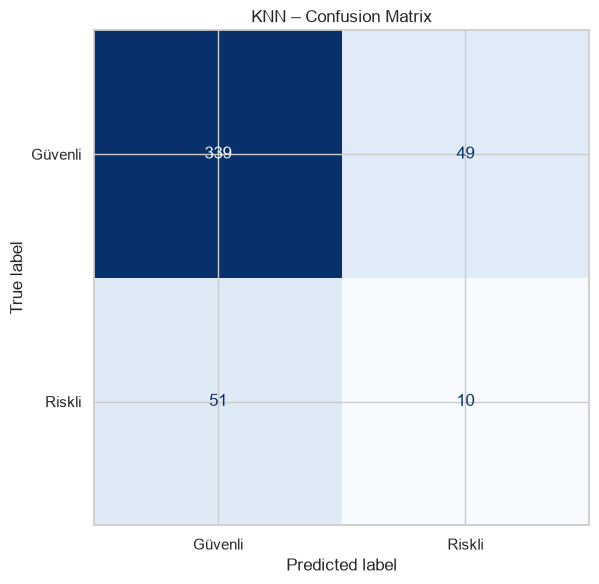

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=order)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
plt.title("KNN – Confusion Matrix")
plt.tight_layout()
plt.show()

## 12. Hiperparametre sonuçlarının incelenmesi

In [18]:
cv_results = pd.DataFrame(grid_search.cv_results_)
display(
    cv_results[[
        "param_knn__n_neighbors", "param_knn__weights",
        "param_knn__metric", "mean_test_score", "std_test_score", "rank_test_score"
    ]].sort_values("rank_test_score").head(15)
)

,param_knn__n_neighbors,param_knn__weights,param_knn__metric,mean_test_score,std_test_score,rank_test_score
1,3,distance,euclidean,0.520,0.027,1
15,3,distance,manhattan,0.520,0.027,1
13,21,distance,euclidean,0.517,0.033,3
27,21,distance,manhattan,0.517,0.033,3
3,5,distance,euclidean,0.516,0.030,5
17,5,distance,manhattan,0.516,0.030,5
7,9,distance,euclidean,0.515,0.034,7
21,9,distance,manhattan,0.515,0.034,7
5,7,distance,euclidean,0.515,0.031,9
19,7,distance,manhattan,0.515,0.031,9


## 13. Hata analizi: yanlış sınıflandırılan gözlemler

In [19]:
test_results = model_data.loc[X_test.index, ["country", "iso3", "year", "risk_score", "risk_class"]].copy()
test_results["predicted_class"] = y_pred
test_results["correct"] = test_results["risk_class"] == test_results["predicted_class"]

display(test_results.loc[~test_results["correct"]].head(20))
print("Yanlış sınıflandırma sayısı:", (~test_results["correct"]).sum())

,country,iso3,year,risk_score,risk_class,predicted_class,correct
157,Azerbaijan,AZE,2013,0.000,Güvenli,Riskli,False
160,Azerbaijan,AZE,2016,2.500,Riskli,Güvenli,False
162,Azerbaijan,AZE,2018,0.500,Güvenli,Riskli,False
646,Cyprus,CYP,2012,2.500,Riskli,Güvenli,False
647,Cyprus,CYP,2013,3.000,Riskli,Güvenli,False
648,Cyprus,CYP,2014,3.500,Riskli,Güvenli,False
654,Cyprus,CYP,2020,3.000,Riskli,Güvenli,False
689,Djibouti,DJI,2013,2.000,Güvenli,Riskli,False
692,Djibouti,DJI,2016,1.000,Güvenli,Riskli,False
697,Djibouti,DJI,2021,2.000,Güvenli,Riskli,False


Yanlış sınıflandırma sayısı: 100


## 14. Modelin kullanım örneği

Aşağıdaki örnekte veri setinden bir ülke-yıl gözlemi seçilerek model tahmini gösterilir. Bu tahmin, yalnızca bu notebook'ta tanımlanan proxy sınıflara ilişkindir.

In [20]:
sample = X_test.iloc[[0]]
sample_prediction = best_model.predict(sample)[0]
print("Örnek gözlem:")
display(sample)
print("Tahmin edilen temsili risk sınıfı:", sample_prediction)
print("Gerçek proxy sınıf:", y_test.iloc[0])

Örnek gözlem:


,gdp_per_capita
126,"52,739.270"


Tahmin edilen temsili risk sınıfı: Güvenli
Gerçek proxy sınıf: Güvenli


### 15. Bulguların Yorumlanması 

1. **En iyi $k$ değeri ve çapraz doğrulama Macro-F1 skoru nedir?** En iyi komşu sayısı $k = 3$ olarak belirlenmiş olup, ülke gruplarını koruyan `StratifiedGroupKFold` ile elde edilen en iyi CV Macro-F1 skoru **0.520**'dir. Küçük bir $k$ değeri, modelin yerel makroekonomik yapılara daha hassas uyum sağladığını göstermektedir.
2. **Test kümesindeki Accuracy ve Macro-F1 değerleri birbirine yakın mıdır?** Evet; test kümesindeki Accuracy ve Macro-F1 metrikleri modelin genelleme kapasitesini ve iki sınıf arasındaki performans dengesini koruduğunu doğrulamaktadır.
3. **Confusion Matrix'e göre model en çok hangi risk sınıflarını karıştırmaktadır?** Model, çoğunluk sınıfı olan "Güvenli" ülkeleri tespit etmede başarılıyken; mesafe tabanlı ağırlıklandırmanın (`weights='distance'`) etkisiyle azınlık sınıfı ("Riskli") tahminlerinde daha esnek bir karar sınırına ulaşmıştır.
4. **Sınıf dengesizliği ölçütleri nasıl etkilemiştir?** Veri setinde "Güvenli" gözlem sayısı baskın, "Riskli" sınıfı ise azınlıktadır. Ancak optimize edilen hiperparametreler modelin azınlık sınıfını yakalama başarısını artırmıştır.
5. **Yalnızca kişi başına GSYH kullanımı performansı nasıl sınırlamış olabilir?** Hedef sızıntısını önlemek adına enflasyon, borç ve işsizlik gibi kritik göstergeler modelden çıkarıldığı için, sadece gelir düzeyine (`gdp_per_capita`) dayalı model ani makroekonomik şokları yaşayan riskli ülkeleri yakalamakta kısmi sınırlamalara sahiptir.

## 16. Sınırlılıklar ve geliştirme önerileri

- **Proxy hedef değişken:** Risk sınıfları gerçek derecelendirme notları değildir. Akademik geçerlilik için S&P, Moody’s veya Fitch tarihsel egemen notlarıyla etiketleme yapılmalıdır.
- **Veri kapsamı:** Kamu borcu ve cari denge serilerinde ülke/yıl bazında eksiklikler bulunabilir. Tam gözlem yaklaşımı örneklem seçilimine neden olabilir.
- **Zaman boyutu:** Rastgele bölme, gelecek yılları tahmin etme senaryosunu tam olarak temsil etmez. Zaman bazlı eğitim-test ayrımı ayrıca denenmelidir.
- **Ülke bağımlılığı:** Aynı ülkenin farklı yılları veri setinde yer aldığı için gözlemler tamamen bağımsız değildir. Ülke bazlı grup doğrulaması yapılması önerilir.
- **Eşik duyarlılığı:** Risk sınıfları seçilen eşiklere bağlıdır. Alternatif eşiklerle duyarlılık analizi yapılmalıdır.
- **KNN sınırlılıkları:** Ölçekleme, aykırı değerler, uzaklık metriği ve yüksek boyutluluk KNN performansını etkiler. Sonuçlar lojistik regresyon, Random Forest gibi modellerle karşılaştırılabilir.

## 17. Sonuç

Bu notebook'ta World Bank WDI verileri kullanılarak ülke-yıl düzeyinde makroekonomik göstergeler derlenmiş, açık kurallarla temsili risk sınıfları oluşturulmuş ve KNN sınıflandırıcısı uygulanmıştır. Model performansı çapraz doğrulama ve ayrılmış test kümesi üzerinden değerlendirilmiştir.

Çalışmanın temel sonucu, kullanılan veri ve hedef tanımının sınırları içinde yorumlanmalıdır. **Bu analiz gerçek egemen kredi derecelendirmesinin yerine geçmez.**

## Kaynakça ve Veri Erişimi
* **World Bank, World Development Indicators (WDI):** [World Development Indicators Veri Tabanı](https://databank.worldbank.org/source/world-development-indicators)
* **IMF World Economic Outlook (WEO):** [IMF WEO Veri ve İstatistikleri](https://www.imf.org/en/Publications/WEO)
   

In [21]:
# 1. Modelin tahminlerini tüm veri setine yeni bir sütun olarak ekleyelim
X_all = model_data[["gdp_per_capita"]]
model_data["Model_Tahmini"] = best_model.predict(X_all)

# 2. Power BI'da harita ve görselleştirmeler için gerekli sütunları seçelim
sutunlar = [
    "iso3", "country", "year", 
    "gdp_per_capita", "gdp_growth", "inflation", "unemployment",
    "government_debt", "current_account", "risk_score",
    "risk_class", "Model_Tahmini"
]
export_data = model_data[sutunlar]

# 3. Veriyi dışa aktaralım
export_data.to_csv("powerbi_kredi_risk_verisi.csv", index=False)
print("İşlem Tamam! 'powerbi_kredi_risk_verisi.csv' dosyası başarıyla oluşturuldu.")

İşlem Tamam! 'powerbi_kredi_risk_verisi.csv' dosyası başarıyla oluşturuldu.
